# Repeatable Speed, Uncertain Added Value
## Combine tracking to rookie receiver route speed

**Question:** Do tracking-derived 40-yard features add information beyond official
40-yard time, height and weight when predicting rookie receivers' in-game route speed?

This notebook reproduces the full analysis from the nine competition CSV files.
It streams the large game files in chunks, needs no internet, and uses CPU only.
Attach the **NFL Big Data Bowl 2027** competition data and run all cells.
No external datasets or pretrained models are used.

**Scope:** This is exploratory research, not a claim of overall player quality.
Earlier curl-to-separation analyses did not demonstrate incremental predictive value.
This speed analysis retains both evaluation years and its unsuccessful checks.


In [1]:
import os
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Image, Markdown

if os.environ.get('NFL_DATA_DIR'):
    DATA_DIR = Path(os.environ['NFL_DATA_DIR'])
else:
    candidates = [Path.cwd() / 'data/nfl-big-data-bowl-2027',
                  Path.cwd().parent / 'data/nfl-big-data-bowl-2027']
    DATA_DIR = next((p for p in candidates if (p / 'players.csv').exists()), None)
    if DATA_DIR is None and Path('/kaggle/input').exists():
        matches = list(Path('/kaggle/input').rglob('combine_tracking.csv'))
        if len(matches) != 1:
            raise RuntimeError('Attach exactly one competition dataset, or set NFL_DATA_DIR.')
        DATA_DIR = matches[0].parent
    if DATA_DIR is None:
        raise FileNotFoundError('Competition CSVs not found; set NFL_DATA_DIR to their directory.')

WORK_DIR = Path(os.environ.get('NFL_WORK_DIR', '/kaggle/working' if Path('/kaggle').exists()
                            else str(Path.cwd() / 'notebook_output')))
WORK_DIR.mkdir(parents=True, exist_ok=True)
required = ['players.csv', 'combine_results.csv', 'combine_tracking.csv', 'games.csv',
            'player_play.csv'] + [f'game_tracking_{y}.csv' for y in (2023, 2024, 2025)]
assert all((DATA_DIR / f).is_file() for f in required), 'Missing competition files'
print({'python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'sklearn': sklearn.__version__,
       'data_directory': str(DATA_DIR), 'output_directory': str(WORK_DIR)})


{'python': '3.10.11', 'numpy': '2.2.6', 'pandas': '2.2.3', 'sklearn': '1.7.2', 'data_directory': 'D:\\NFL\\data\\nfl-big-data-bowl-2027', 'output_directory': 'D:\\NFL\\verification\\notebook_run'}


## 1. Fixed primary design and measurement

We use wide receivers' **rookie regular seasons**, not cumulative careers. The
game outcome is the 95th percentile of a three-frame median-smoothed speed stream
from snap until the throw, capped at four seconds. A play needs a route label,
one snap, one throw, at least two seconds and twenty frames, no duplicate timestamps
or gaps above 0.21 seconds, and no nullifying penalty. The player must have at least
30 accepted plays and tracked 40-yard data.

Combine peak speed uses the same smoothing and percentile. The early-speed proxy
is speed one second after the first observed speed of at least 1 in the supplied
units. Both features are median-aggregated across attempts. This is **not an official
timed acceleration split**. We record attempts that already start above the threshold.

Before any speed-outcome results were computed, the windows, features, sample threshold,
models and year splits were recorded in the project design. We retain native speed
units because the official data dictionary could not be retrieved during this run.
Coordinate-derived speeds are checked against supplied speed, but that does not
independently establish the physical unit.


In [2]:
"""Extract WR Combine and rookie pre-throw route speed with explicit QA."""
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = WORK_DIR
DATA = DATA_DIR
OUT = ROOT / "data/processed"
REPORT = ROOT / "reports/speed_study"
KEYS = ["game_id", "play_id", "nfl_id"]


def combine_features(players):
    tracking = pd.read_csv(DATA / "combine_tracking.csv")
    tracking = tracking.loc[tracking.entity_type.eq("PLAYER") &
                            tracking.nfl_id.isin(players.nfl_id) &
                            tracking.drill_name.eq("FORTY_YARD_DASH")].copy()
    tracking["time"] = pd.to_datetime(tracking.time)
    output, rejected = [], []
    for key, g in tracking.groupby(["nfl_id", "event_id", "attempt"]):
        g = g.sort_values("time")
        t = (g.time - g.time.iloc[0]).dt.total_seconds().to_numpy()
        s = g.s.rolling(3, center=True, min_periods=1).median().to_numpy()
        onset = np.flatnonzero(s >= 1)
        reason = None
        if len(g) < 20 or not len(onset) or not np.isfinite(s).all() or (s < 0).any():
            reason = "invalid_or_short"
        elif np.any(np.diff(t) <= 0) or np.max(np.diff(t)) > .21:
            reason = "duplicate_time_or_gap"
        elif t[onset[0]] + 1 > t[-1]:
            reason = "short_onset_window"
        if reason:
            rejected.append({"nfl_id": key[0], "event_id": key[1], "attempt": key[2], "reason": reason})
            continue
        coordinate_speed = np.linalg.norm(np.diff(g[["x", "y"]].to_numpy(), axis=0), axis=1) / np.diff(t)
        mask = s[1:] > 2
        output.append({"nfl_id": key[0], "event_id": key[1], "attempt": key[2],
                       "combine_peak_speed": float(np.quantile(s, .95)),
                       "combine_early_speed": float(np.interp(t[onset[0]] + 1, t, s)),
                       "initial_speed": float(g.s.iloc[0]),
                       "onset_already_above_threshold": bool(g.s.iloc[0] >= 1),
                       "duration": t[-1],
                       "coordinate_to_s_ratio": float(np.median(coordinate_speed[mask] / s[1:][mask]))})
    frame = pd.DataFrame(output)
    frame.to_csv(OUT / "combine_speed_attempts.csv", index=False)
    pd.DataFrame(rejected).to_csv(REPORT / "combine_rejected.csv", index=False)
    frame.groupby("nfl_id")[["combine_peak_speed", "combine_early_speed"]].median().to_csv(
        OUT / "combine_speed_players.csv")
    return {"attempts": len(frame), "players": frame.nfl_id.nunique(), "rejected": len(rejected),
            "onset_already_above_threshold_attempts": int(frame.onset_already_above_threshold.sum()),
            "coordinate_to_s_ratio_median": frame.coordinate_to_s_ratio.median()}


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    REPORT.mkdir(parents=True, exist_ok=True)
    players = pd.read_csv(DATA / "players.csv")
    players = players.loc[players.nfl_position.eq("WR")]
    combine_qa = combine_features(players)
    games = pd.read_csv(DATA / "games.csv")
    cols = KEYS + ["route_ran", "team_coverage_man_zone", "cushion", "play_nullified_by_penalty"]
    metadata = pd.read_csv(DATA / "player_play.csv", usecols=cols)
    assert not metadata.duplicated(KEYS).any(), "Duplicate player-play metadata"
    metadata = metadata.merge(players[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
    metadata = metadata.merge(games[["game_id", "season", "season_type"]], on="game_id", validate="many_to_one")
    metadata = metadata.loc[metadata.season_type.eq("REG") & metadata.season.eq(metadata.draft_year) &
                            metadata.play_nullified_by_penalty.eq("N") & metadata.route_ran.notna()]
    all_output, year_audits, rejected = [], [], []
    for year in (2023, 2024, 2025):
        year_meta = metadata.loc[metadata.season.eq(year)].copy()
        wanted = pd.MultiIndex.from_frame(year_meta[KEYS])
        frames, scanned, events = [], 0, Counter()
        for chunk in pd.read_csv(DATA / f"game_tracking_{year}.csv",
                                 usecols=KEYS + ["time", "s", "x", "y", "event"], chunksize=300000):
            scanned += len(chunk)
            chunk = chunk.loc[chunk.nfl_id.isin(year_meta.nfl_id)]
            chunk = chunk.loc[pd.MultiIndex.from_frame(chunk[KEYS]).isin(wanted)].copy()
            if len(chunk):
                frames.append(chunk)
                events.update(chunk.event.dropna().value_counts().to_dict())
        selected = pd.concat(frames, ignore_index=True)
        selected["time"] = pd.to_datetime(selected.time)
        counts = Counter()
        tracked_keys = pd.MultiIndex.from_frame(selected[KEYS].drop_duplicates())
        missing = year_meta.loc[~pd.MultiIndex.from_frame(year_meta[KEYS]).isin(tracked_keys)]
        counts["missing_tracking"] = len(missing)
        for row in missing[KEYS].to_dict("records"):
            rejected.append({**row, "season": year, "reason": "missing_tracking"})
        coordinate_ratios = []
        for key, g in selected.groupby(KEYS, sort=False):
            g = g.sort_values("time")
            snaps = g.loc[g.event.eq("ball_snap"), "time"]
            throws = g.loc[g.event.eq("pass_forward"), "time"]
            reason = None
            if len(snaps) != 1 or len(throws) != 1:
                reason = "missing_or_multiple_snap_throw"
            elif g.time.duplicated().any():
                reason = "duplicate_frame_time"
            if reason:
                counts[reason] += 1
                rejected.append(dict(zip(KEYS, key), season=year, reason=reason))
                continue
            start, throw = snaps.iloc[0], throws.iloc[0]
            end = min(throw, start + pd.Timedelta(seconds=4))
            live = g.loc[g.time.ge(start) & g.time.le(end)].copy()
            duration = (end - start).total_seconds()
            if duration < 2 or len(live) < 20:
                reason = "short_prethrow_window"
            elif (live.time.diff().dt.total_seconds().dropna() > .21).any():
                reason = "frame_gap"
            elif not np.isfinite(live.s).all() or live.s.lt(0).any():
                reason = "invalid_speed"
            if reason:
                counts[reason] += 1
                rejected.append(dict(zip(KEYS, key), season=year, reason=reason))
                continue
            smooth = live.s.rolling(3, center=True, min_periods=1).median()
            dt = live.time.diff().dt.total_seconds().to_numpy()[1:]
            coordinate = np.linalg.norm(np.diff(live[["x", "y"]].to_numpy(), axis=0), axis=1) / dt
            mask = live.s.to_numpy()[1:] > 2
            if mask.any():
                coordinate_ratios.append(float(np.median(coordinate[mask] / live.s.to_numpy()[1:][mask])))
            all_output.append(dict(zip(KEYS, key), game_peak_speed=float(smooth.quantile(.95)),
                                   snap_speed=float(live.s.iloc[0]), window_duration=duration,
                                   frame_count=len(live)))
            counts["accepted"] += 1
        year_audits.append({"season": year, "scanned_rows": scanned, "selected_rows": len(selected),
                            "metadata_plays": len(year_meta), "tracked_plays": selected.groupby(KEYS).ngroups,
                            "counts": dict(counts), "events": dict(events),
                            "coordinate_to_s_ratio_median": float(np.median(coordinate_ratios))})
        print(f"{year}: {dict(counts)}", flush=True)
    result = pd.DataFrame(all_output).merge(metadata, on=KEYS, validate="one_to_one")
    assert len(result) + len(rejected) == len(metadata), "Every eligible play must be accounted for"
    result["window_duration_sq"] = result.window_duration ** 2
    result.to_csv(OUT / "rookie_wr_route_speed.csv", index=False)
    pd.DataFrame(rejected).to_csv(REPORT / "game_rejected.csv", index=False)
    report = {"combine": combine_qa, "game_years": year_audits,
              "accepted_game_plays": len(result), "accepted_game_players": result.nfl_id.nunique()}
    (REPORT / "extraction_audit.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2))


main()


2023: {'missing_tracking': 16, 'accepted': 5618, 'short_prethrow_window': 910, 'missing_or_multiple_snap_throw': 872}


2024: {'missing_tracking': 17, 'accepted': 3865, 'missing_or_multiple_snap_throw': 681, 'short_prethrow_window': 638}


2025: {'missing_tracking': 5, 'accepted': 3205, 'short_prethrow_window': 486, 'missing_or_multiple_snap_throw': 531}


{
  "combine": {
    "attempts": 174,
    "players": 93,
    "rejected": 0,
    "onset_already_above_threshold_attempts": 7,
    "coordinate_to_s_ratio_median": 0.9932676203719493
  },
  "game_years": [
    {
      "season": 2023,
      "scanned_rows": 3665443,
      "selected_rows": 562475,
      "metadata_plays": 7416,
      "tracked_plays": 7400,
      "counts": {
        "missing_tracking": 16,
        "accepted": 5618,
        "short_prethrow_window": 910,
        "missing_or_multiple_snap_throw": 872
      },
      "events": {
        "ball_snap": 7397,
        "pass_forward": 6533,
        "pass_arrived": 5056,
        "pass_outcome_caught": 3925,
        "tackle": 3195,
        "first_contact": 3005,
        "pass_outcome_incomplete": 2280,
        "play_action": 1373,
        "out_of_bounds": 1118,
        "autoevent_passinterrupted": 848,
        "qb_sack": 466,
        "run": 368,
        "touchdown": 143,
        "dropped_pass": 173,
        "pass_outcome_touchdown": 145,
 

## 2. Forward-year evaluation

Train on 2023 to evaluate 2024; train on 2023–2024 to evaluate 2025. Players never
cross train/test. A training-only ridge model adjusts each play's speed for route,
coverage, window duration and its square, snap speed and cushion. Each player's
mean residual is the prediction target. This is a contextual speed measure,
not separation, receiving production or a causal ability score.

Compare a training-mean reference, official 40 time + height + weight, and those
three features plus the two tracking measures. All ridge penalties are fixed at
10; imputation and scaling use training data only. Each player has equal evaluation
weight. Report MAE and RMSE, with a paired player-bootstrap interval on the MAE
improvement. These intervals condition on fitted models and omit training uncertainty.


In [3]:
"""Fixed-design forward-year analysis of Combine-to-rookie route speed."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = WORK_DIR
DATA = DATA_DIR
PROCESSED = ROOT / "data/processed"
OUT = ROOT / "reports/speed_study"
BASE = ["forty", "combine_height", "combine_weight"]
SENSOR = ["combine_peak_speed", "combine_early_speed"]
CAT = ["route_ran", "team_coverage_man_zone"]
NUM = ["window_duration", "window_duration_sq", "snap_speed", "cushion"]


def player_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))


def context_model():
    return make_pipeline(ColumnTransformer([
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore")), CAT),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    ]), Ridge(alpha=10, solver="lsqr"))


def errors(pred, name):
    error = pred.target - pred[name]
    return {name + "_mae": float(error.abs().mean()),
            name + "_rmse": float(np.sqrt((error ** 2).mean()))}


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    players = pd.read_csv(DATA / "players.csv")
    combine = pd.read_csv(DATA / "combine_results.csv")
    sensor = pd.read_csv(PROCESSED / "combine_speed_players.csv")
    plays = pd.read_csv(PROCESSED / "rookie_wr_route_speed.csv")
    counts = plays.groupby("nfl_id").size()
    table = players.merge(combine, on=["nfl_id", "draft_year"], validate="one_to_one")
    table = table.merge(sensor, on="nfl_id", validate="one_to_one")
    table = table.loc[table.nfl_position.eq("WR") & table.nfl_id.isin(counts[counts >= 30].index)].copy()
    table["valid_game_plays"] = table.nfl_id.map(counts)
    plays = plays.loc[plays.nfl_id.isin(table.nfl_id)].copy()
    assert np.isfinite(table[SENSOR].to_numpy()).all()
    assert not plays.duplicated(["game_id", "play_id", "nfl_id"]).any()
    table.to_csv(OUT / "player_features.csv", index=False)
    summary, outputs, coefficients = [], [], []
    for year in (2024, 2025):
        train_p = plays.loc[plays.draft_year.lt(year)].copy()
        test_p = plays.loc[plays.draft_year.eq(year)].copy()
        context = context_model()
        context.fit(train_p[CAT + NUM], train_p.game_peak_speed)
        for frame in (train_p, test_p):
            frame["context_prediction"] = context.predict(frame[CAT + NUM])
            frame["target"] = frame.game_peak_speed - frame.context_prediction
        train = table.merge(train_p.groupby("nfl_id").target.mean(), on="nfl_id")
        test = table.merge(test_p.groupby("nfl_id").target.mean(), on="nfl_id")
        assert train.draft_year.max() < test.draft_year.min()
        assert set(train.nfl_id).isdisjoint(test.nfl_id)
        if len(train) < 12 or len(test) < 5:
            raise ValueError(f"Insufficient primary sample for {year}: {len(train)}/{len(test)}")
        pred = test[["nfl_id", "display_name", "draft_year", "valid_game_plays", "target"]].copy()
        pred["mean_reference"] = train.target.mean()
        for label, columns in [("traditional", BASE), ("with_tracking", BASE + SENSOR)]:
            model = player_model()
            model.fit(train[columns], train.target)
            pred[label] = model.predict(test[columns])
            for feature, coefficient in zip(columns, model.named_steps["ridge"].coef_):
                coefficients.append({"test_year": year, "model": label, "feature": feature,
                                     "standardized_coefficient": coefficient})
        delta = ((pred.target - pred.traditional).abs() - (pred.target - pred.with_tracking).abs()).to_numpy()
        rng = np.random.default_rng(2027)
        boot = rng.choice(delta, size=(5000, len(delta)), replace=True).mean(axis=1)
        record = {"test_year": year, "train_players": len(train), "test_players": len(test),
                  "train_plays": len(train_p), "test_plays": len(test_p),
                  "movement_mae_improvement": float(delta.mean()),
                  "ci_low": float(np.quantile(boot, .025)), "ci_high": float(np.quantile(boot, .975)),
                  "context_play_test_mae": float((test_p.game_peak_speed - test_p.context_prediction).abs().mean())}
        for name in ["mean_reference", "traditional", "with_tracking"]:
            record.update(errors(pred, name))
        summary.append(record)
        outputs.append(pred)
    predictions = pd.concat(outputs, ignore_index=True)
    scores = pd.DataFrame(summary)
    scores.to_csv(OUT / "forward_year_scores.csv", index=False)
    predictions.to_csv(OUT / "forward_year_predictions.csv", index=False)
    pd.DataFrame(coefficients).to_csv(OUT / "model_coefficients.csv", index=False)

    # Descriptive repeatability across disjoint alternating games.
    game_order = plays[["nfl_id", "game_id"]].drop_duplicates().sort_values(["nfl_id", "game_id"])
    game_order["half"] = game_order.groupby("nfl_id").cumcount() % 2
    split = plays.merge(game_order, on=["nfl_id", "game_id"], validate="many_to_one")
    halves = split.groupby(["nfl_id", "half"]).game_peak_speed.agg(["mean", "size"]).unstack()
    eligible = halves["size"].ge(10).all(axis=1)
    means = halves.loc[eligible, "mean"]
    game_reliability = float(means[0].corr(means[1]))
    means.to_csv(OUT / "game_split_half_means.csv")
    attempts = pd.read_csv(PROCESSED / "combine_speed_attempts.csv").sort_values(["nfl_id", "attempt", "event_id"])
    attempts["repeat_index"] = attempts.groupby("nfl_id").cumcount()
    repeats = attempts.loc[attempts.repeat_index.lt(2)].pivot(index="nfl_id", columns="repeat_index", values=SENSOR)
    repeat_corr = {column: float(repeats[column][0].corr(repeats[column][1])) for column in SENSOR}
    raw = table.merge(plays.groupby("nfl_id").game_peak_speed.mean(), on="nfl_id")
    raw.to_csv(OUT / "descriptive_player_means.csv", index=False)
    corr = raw[BASE + SENSOR + ["game_peak_speed"]].corr()
    corr.to_csv(OUT / "descriptive_correlations.csv")
    info = {"status": "exploratory", "primary_players": len(table), "primary_plays": len(plays),
            "players_by_year": {str(k): int(v) for k, v in table.groupby("draft_year").size().items()},
            "missing_classic_features": table[BASE].isna().sum().to_dict(),
            "game_split_half_players": int(eligible.sum()), "game_split_half_correlation": game_reliability,
            "combine_repeat_correlations": repeat_corr,
            "combine_players_with_two_attempts": int(repeats[SENSOR[0]].dropna().shape[0]),
            "raw_peak_game_correlation": float(corr.loc["combine_peak_speed", "game_peak_speed"]),
            "scores": summary,
            "limitations": ["Route speed is not overall football success or receiver separation.",
                            "All analyses exploratory; earlier outcomes from these years were inspected.",
                            "Bootstrap is conditional on fitted folds and ignores training uncertainty.",
                            "Only participating Combine players and observed rookie pass routes are included.",
                            "Pre-throw window restriction selects longer-developing pass plays.",
                            "Additive context model does not remove all team, route depth, or tactical effects.",
                            "Official speed units are not yet verified."]}
    (OUT / "summary.json").write_text(json.dumps(info, indent=2), encoding="utf-8")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for year, group in raw.groupby("draft_year"):
        axes[0].scatter(group.combine_peak_speed, group.game_peak_speed, label=str(year), alpha=.8)
    axes[0].set(xlabel="Combine 40-yard tracking peak speed", ylabel="Mean rookie pre-throw route peak speed",
                title="Descriptive association (not context adjusted)")
    axes[0].legend(title="Draft year")
    x = np.arange(len(scores))
    for i, (name, label) in enumerate([("mean_reference", "Mean"), ("traditional", "Classic"),
                                      ("with_tracking", "Classic + tracking")]):
        axes[1].bar(x + (i - 1) * .25, scores[name + "_mae"], width=.25, label=label)
    axes[1].set(xticks=x, xticklabels=scores.test_year.astype(str), ylabel="Player MAE (lower is better)",
                title="Forward-year, context-adjusted prediction")
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / "speed_transfer_results.png", dpi=160)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(means[0], means[1], alpha=.7)
    ax.set(xlabel="Mean speed: alternating games, half 1", ylabel="Mean speed: alternating games, half 2",
           title=f"Raw outcome stability: r={game_reliability:.2f}, n={len(means)}")
    fig.tight_layout()
    fig.savefig(OUT / "game_speed_reliability.png", dpi=160)
    plt.close(fig)
    print(json.dumps(info, indent=2))


main()


{
  "status": "exploratory",
  "primary_players": 58,
  "primary_plays": 10944,
  "players_by_year": {
    "2023": 22,
    "2024": 20,
    "2025": 16
  },
  "missing_classic_features": {
    "forty": 0,
    "combine_height": 0,
    "combine_weight": 0
  },
  "game_split_half_players": 58,
  "game_split_half_correlation": 0.6202118587095797,
  "combine_repeat_correlations": {
    "combine_peak_speed": 0.8931452350329658,
    "combine_early_speed": 0.15267261194472365
  },
  "combine_players_with_two_attempts": 81,
  "raw_peak_game_correlation": 0.3822496201825323,
  "scores": [
    {
      "test_year": 2024,
      "train_players": 22,
      "test_players": 20,
      "train_plays": 4173,
      "test_plays": 3795,
      "movement_mae_improvement": 0.027302466726190477,
      "ci_low": -0.0007834662335713567,
      "ci_high": 0.0538835502984431,
      "context_play_test_mae": 0.7910185694210973,
      "mean_reference_mae": 0.1937610255876501,
      "mean_reference_rmse": 0.2263554610643953

,test_year,train_players,test_players,train_plays,test_plays,movement_mae_improvement,ci_low,ci_high,context_play_test_mae,mean_reference_mae,mean_reference_rmse,traditional_mae,traditional_rmse,with_tracking_mae,with_tracking_rmse
0,2024,22,20,4173,3795,0.027302,-0.000783,0.053884,0.791019,0.193761,0.226355,0.180840,0.212366,0.153537,0.192700
1,2025,42,16,7968,2976,-0.003718,-0.021071,0.014158,0.750338,0.156857,0.193783,0.140512,0.171716,0.144229,0.169979


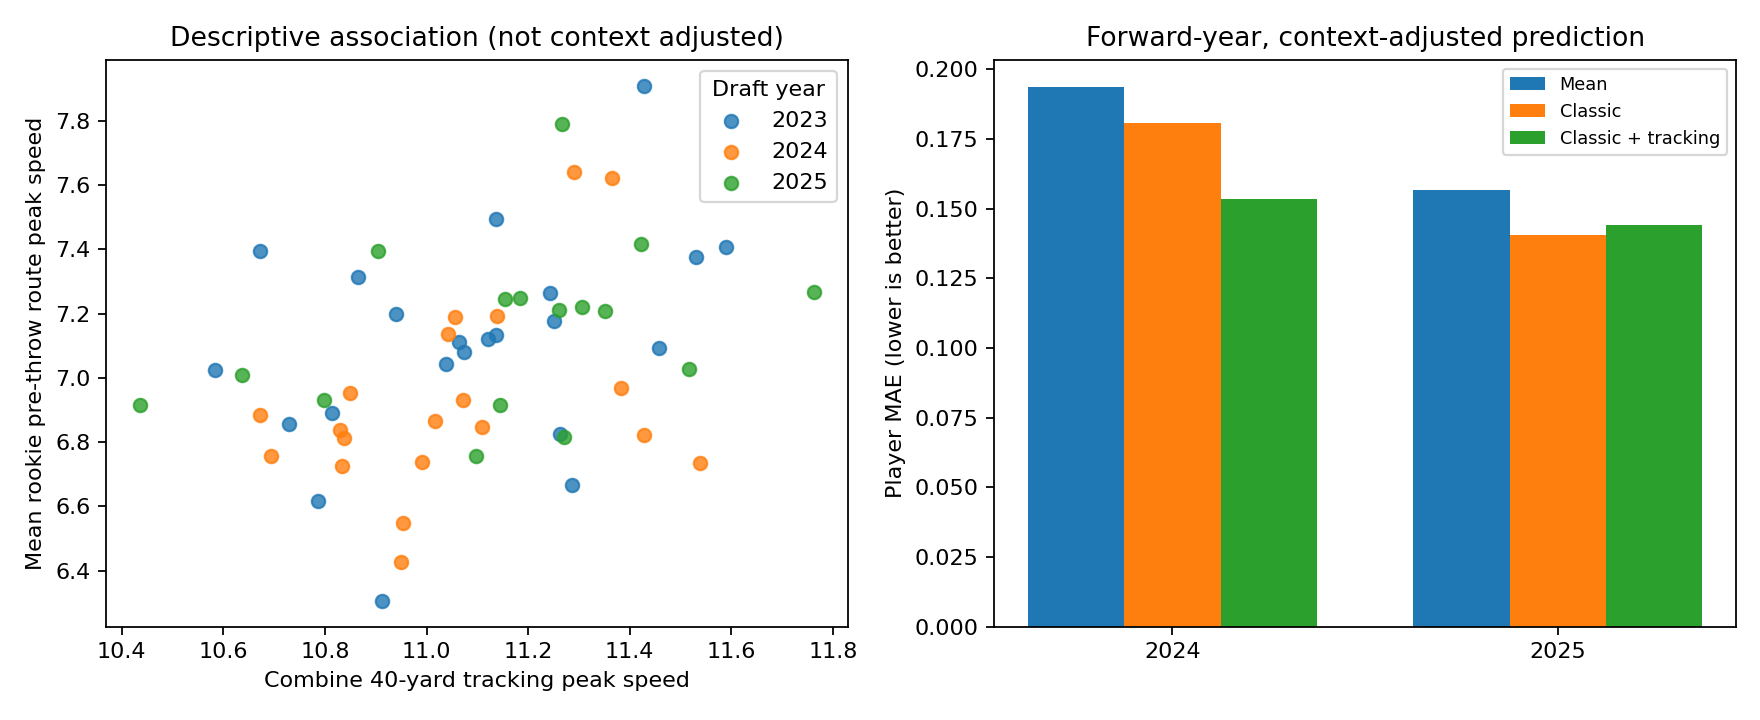

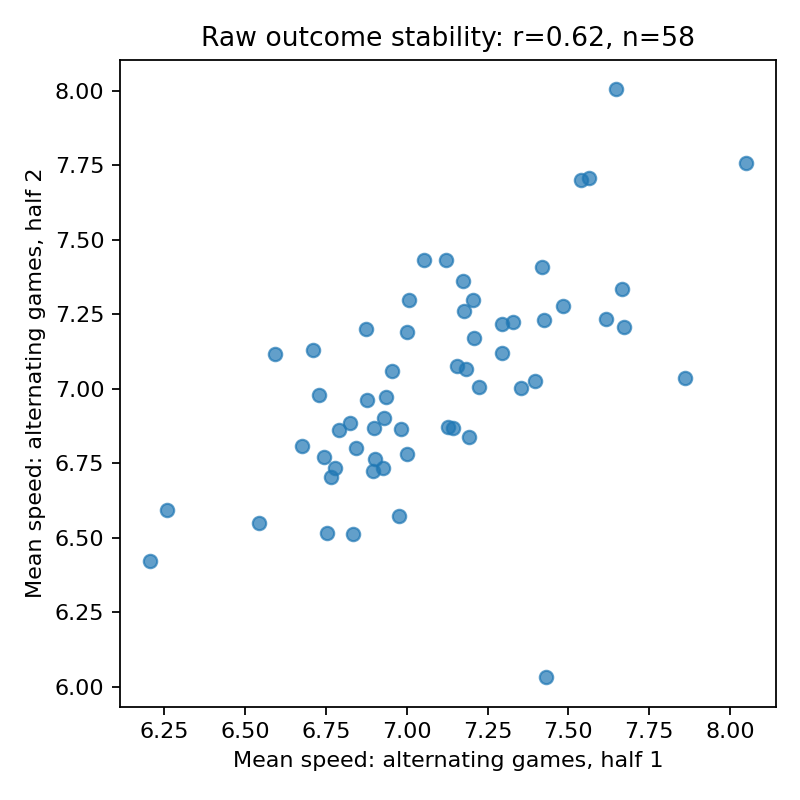

In [4]:
display(pd.read_csv(WORK_DIR / 'reports/speed_study/forward_year_scores.csv'))
display(Image(filename=str(WORK_DIR / 'reports/speed_study/speed_transfer_results.png')))
display(Image(filename=str(WORK_DIR / 'reports/speed_study/game_speed_reliability.png')))


## 3. Clearly labelled post-hoc diagnostics

After inspecting the primary results, we examine within-year associations, paired
Combine attempts, and a single ablation that removes the low-repeatability early-speed
proxy. These are descriptive/diagnostic checks, not a replacement primary analysis
or new independent validation. All checked years are retained.


In [5]:
"""Explicitly post-hoc diagnostics; they do not replace the primary design."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


ROOT = WORK_DIR
DATA = DATA_DIR
PROCESSED = ROOT / "data/processed"
OUT = ROOT / "reports/speed_study"


def correlation_interval(x, y, seed=2027):
    values = np.column_stack([x, y])
    values = values[np.isfinite(values).all(axis=1)]
    rng = np.random.default_rng(seed)
    stats = []
    for _ in range(3000):
        sample = values[rng.integers(0, len(values), len(values))]
        if sample[:, 0].std() > 0 and sample[:, 1].std() > 0:
            stats.append(np.corrcoef(sample.T)[0, 1])
    return {"n": len(values), "r": float(np.corrcoef(values.T)[0, 1]),
            "ci_low": float(np.quantile(stats, .025)), "ci_high": float(np.quantile(stats, .975))}


def main():
    raw = pd.read_csv(OUT / "descriptive_player_means.csv")
    correlations = []
    for year, g in [("pooled", raw)] + list(raw.groupby("draft_year")):
        correlations.append({"comparison": "combine_peak_vs_game_speed", "year": str(year),
                             **correlation_interval(g.combine_peak_speed, g.game_peak_speed)})
    demeaned = raw[["combine_peak_speed", "game_peak_speed"]] - raw.groupby("draft_year")[[
        "combine_peak_speed", "game_peak_speed"]].transform("mean")
    correlations.append({"comparison": "combine_peak_vs_game_speed", "year": "within_year_demeaned",
                         **correlation_interval(demeaned.combine_peak_speed, demeaned.game_peak_speed)})
    correlations.append({"comparison": "combine_peak_vs_official_forty", "year": "pooled",
                         **correlation_interval(raw.combine_peak_speed, raw.forty)})

    players = pd.read_csv(DATA / "players.csv")
    attempts = pd.read_csv(PROCESSED / "combine_speed_attempts.csv").merge(
        players[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
    attempts = attempts.sort_values(["nfl_id", "attempt", "event_id"])
    attempts["repeat_index"] = attempts.groupby("nfl_id").cumcount()
    pairs = attempts.loc[attempts.repeat_index.lt(2)].pivot(
        index=["nfl_id", "draft_year"], columns="repeat_index",
        values=["combine_peak_speed", "combine_early_speed"])
    repeat_records = []
    for feature in ["combine_peak_speed", "combine_early_speed"]:
        values = pairs[feature].dropna()
        for year, g in [("pooled", values)] + list(values.groupby(level="draft_year")):
            repeat_records.append({"feature": feature, "year": str(year), **correlation_interval(g[0], g[1])})
    attempts.groupby("draft_year")[["combine_peak_speed", "combine_early_speed"]].agg(
        ["count", "median", "std", "min", "max"]).to_csv(OUT / "speed_feature_year_distributions.csv")

    # A single diagnostic ablation, motivated by low observed early-speed repeatability.
    table = pd.read_csv(OUT / "player_features.csv")
    plays = pd.read_csv(PROCESSED / "rookie_wr_route_speed.csv")
    plays = plays.loc[plays.nfl_id.isin(table.nfl_id)].copy()
    ablation = []
    for year in (2024, 2025):
        train_p, test_p = plays.loc[plays.draft_year.lt(year)].copy(), plays.loc[plays.draft_year.eq(year)].copy()
        context = context_model().fit(train_p[CAT + NUM], train_p.game_peak_speed)
        for frame in (train_p, test_p):
            frame["target"] = frame.game_peak_speed - context.predict(frame[CAT + NUM])
        train = table.merge(train_p.groupby("nfl_id").target.mean(), on="nfl_id")
        test = table.merge(test_p.groupby("nfl_id").target.mean(), on="nfl_id")
        for label, columns in [("traditional", BASE), ("classic_plus_peak_only_POST_HOC", BASE + ["combine_peak_speed"])]:
            model = player_model().fit(train[columns], train.target)
            prediction = model.predict(test[columns])
            ablation.append({"test_year": year, "model": label, "test_players": len(test),
                             "mae": float(np.mean(np.abs(test.target - prediction))),
                             "rmse": float(np.sqrt(np.mean((test.target - prediction) ** 2)))})
    pd.DataFrame(ablation).to_csv(OUT / "post_hoc_peak_only_ablation.csv", index=False)
    pd.DataFrame(correlations).to_csv(OUT / "correlation_diagnostics.csv", index=False)
    pd.DataFrame(repeat_records).to_csv(OUT / "combine_repeatability_intervals.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    for ax, feature, title in zip(axes, ["combine_peak_speed", "combine_early_speed"],
                                  ["40-yard peak speed", "Early-speed proxy"]):
        values = pairs[feature].dropna()
        for year, group in values.groupby(level="draft_year"):
            ax.scatter(group[0], group[1], label=str(year), alpha=.75)
        lo, hi = values.min().min(), values.max().max()
        ax.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
        record = next(r for r in repeat_records if r["feature"] == feature and r["year"] == "pooled")
        ax.set(xlabel="First tracked attempt", ylabel="Second tracked attempt",
               title=f"{title}: r={record['r']:.2f}, n={record['n']}")
        ax.legend(title="Draft year", fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / "combine_repeatability.png", dpi=160)
    plt.close(fig)
    result = {"status": "post-hoc diagnostics, not a replacement primary analysis",
              "correlations": correlations, "repeatability": repeat_records, "ablation": ablation,
              "interval_note": "Player bootstrap; within-year demeaning fixed before resampling. Exploratory, no multiplicity adjustment."}
    (OUT / "robustness.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    print(json.dumps(result, indent=2))


main()


{
  "status": "post-hoc diagnostics, not a replacement primary analysis",
  "correlations": [
    {
      "comparison": "combine_peak_vs_game_speed",
      "year": "pooled",
      "n": 58,
      "r": 0.38224962018253106,
      "ci_low": 0.1939444027754347,
      "ci_high": 0.5503197449305807
    },
    {
      "comparison": "combine_peak_vs_game_speed",
      "year": "2023",
      "n": 22,
      "r": 0.3825993366954545,
      "ci_low": -0.044928966274262724,
      "ci_high": 0.6634101900154693
    },
    {
      "comparison": "combine_peak_vs_game_speed",
      "year": "2024",
      "n": 20,
      "r": 0.38733957320612333,
      "ci_low": 0.03035319435788228,
      "ci_high": 0.7190904815023876
    },
    {
      "comparison": "combine_peak_vs_game_speed",
      "year": "2025",
      "n": 16,
      "r": 0.3393325458234563,
      "ci_low": -0.04153337357771337,
      "ci_high": 0.6468459461426841
    },
    {
      "comparison": "combine_peak_vs_game_speed",
      "year": "within_year_d

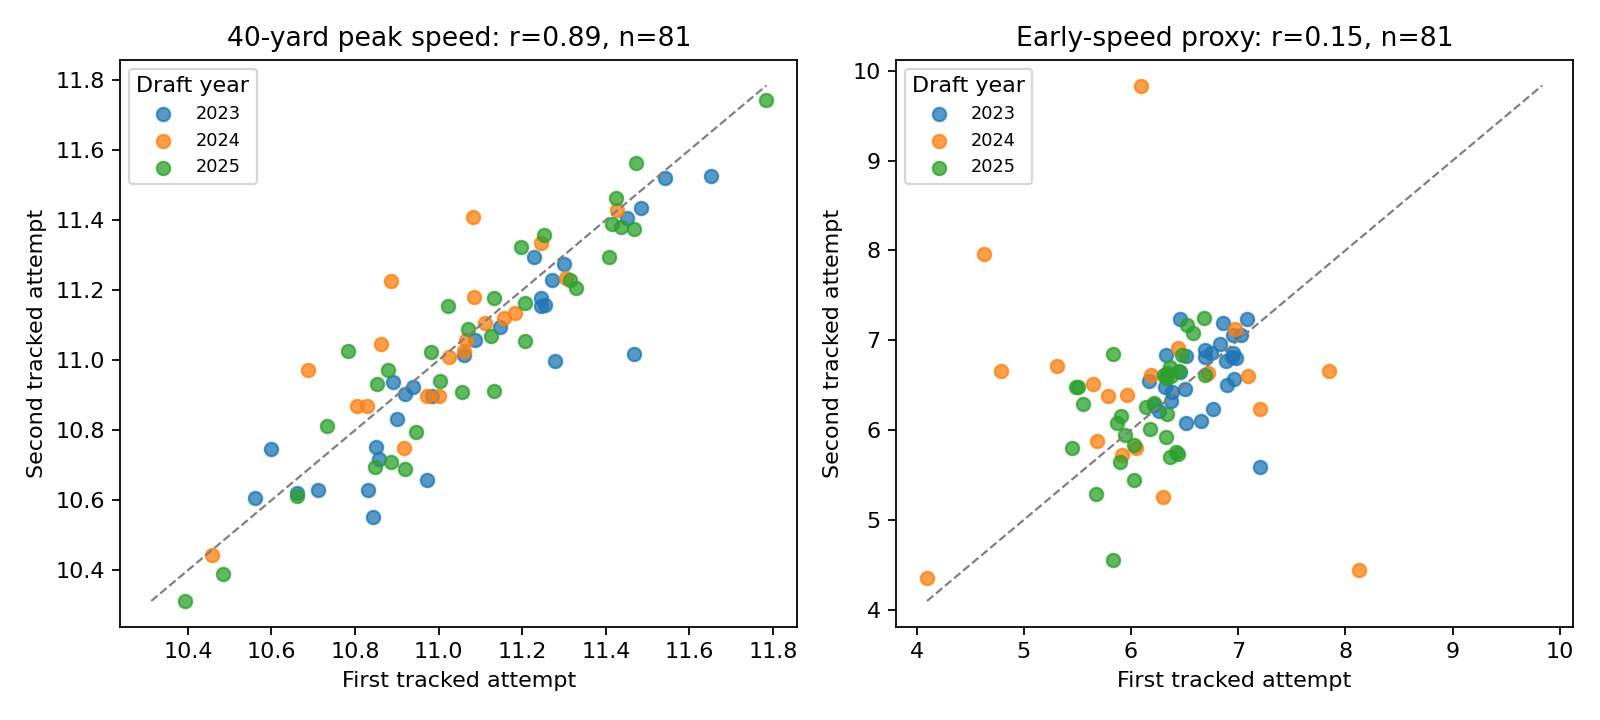

,comparison,year,n,r,ci_low,ci_high
0,combine_peak_vs_game_speed,pooled,58,0.382250,0.193944,0.550320
1,combine_peak_vs_game_speed,2023,22,0.382599,-0.044929,0.663410
2,combine_peak_vs_game_speed,2024,20,0.387340,0.030353,0.719090
3,combine_peak_vs_game_speed,2025,16,0.339333,-0.041533,0.646846
4,combine_peak_vs_game_speed,within_year_demeaned,58,0.365182,0.182335,0.527544
5,combine_peak_vs_official_forty,pooled,58,-0.852180,-0.907434,-0.775621


,test_year,model,test_players,mae,rmse
0,2024,traditional,20,0.180840,0.212366
1,2024,classic_plus_peak_only_POST_HOC,20,0.176974,0.207798
2,2025,traditional,16,0.140512,0.171716
3,2025,classic_plus_peak_only_POST_HOC,16,0.141469,0.166919


In [6]:
display(Image(filename=str(WORK_DIR / 'reports/speed_study/combine_repeatability.png')))
display(pd.read_csv(WORK_DIR / 'reports/speed_study/correlation_diagnostics.csv'))
display(pd.read_csv(WORK_DIR / 'reports/speed_study/post_hoc_peak_only_ablation.csv'))


## 4. Interpretation and limitations

The observed Combine-to-game speed association and high peak-speed repeatability
are useful measurement findings. They do not establish an improvement over existing
scouting measurements: the primary added-feature improvement appears in 2024 but
does not repeat in 2025. Both conditional intervals include zero.

The peak feature overlaps strongly with official 40-yard time. The early-speed proxy
is much less repeatable and depends on an approximate start. Even the post-hoc
peak-only model does not consistently improve MAE. Keep the distinction between
**repeatability**, **association with game movement**, and **incremental prediction**.

For teams: use this as a measurement-validation template before assigning scouting
weight to a new metric. We do not recommend a new player ranking from these results.
Route speed is limited by tactical assignment and opportunity; remaining route-depth,
team and opponent effects are not removed by the additive context model. The sample
excludes nonparticipants and players with few eligible rookie routes; longer-developing
pass plays are preferentially retained. There are only 20 and 16 test players. Prior
exploration used these draft classes, so none is a pristine confirmatory holdout.

The source project retains the earlier curl/separation null results and a complete
experiment register. A separate English writeup reports the numerical conclusions.

### Sources and related work
- [Competition and data](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027)
- [NFL official announcement](https://www.nfl.com/news/big-data-bowl-returns-powered-by-aws)
- [Host discussion on 40-yard tracking timing](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/discussion/751371)
- [Public-work survey: data traps and open angles](https://hackers.pocketplay.win/en/kaggle/nfl-big-data-bowl-2027/)

The public-work survey was consulted after the primary speed results; it describes
prior investigations of start-timing and repeatability. Those ideas are not claimed
as novel here. No public-notebook predictions or derived features were imported.
